В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import random

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
sequence_length = 365 * 4

In [5]:
token_num = 10

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['SOL', 'XLM', 'XRP', 'BTC', 'LINK', 'DOGE', 'DOT', 'ADA', 'ETH', 'XMR']

In [6]:
strategy={"cooldown_long": 90}
# strategy={}

02:27:53 - cmdstanpy - INFO - Chain [1] start processing
02:27:54 - cmdstanpy - INFO - Chain [1] done processing


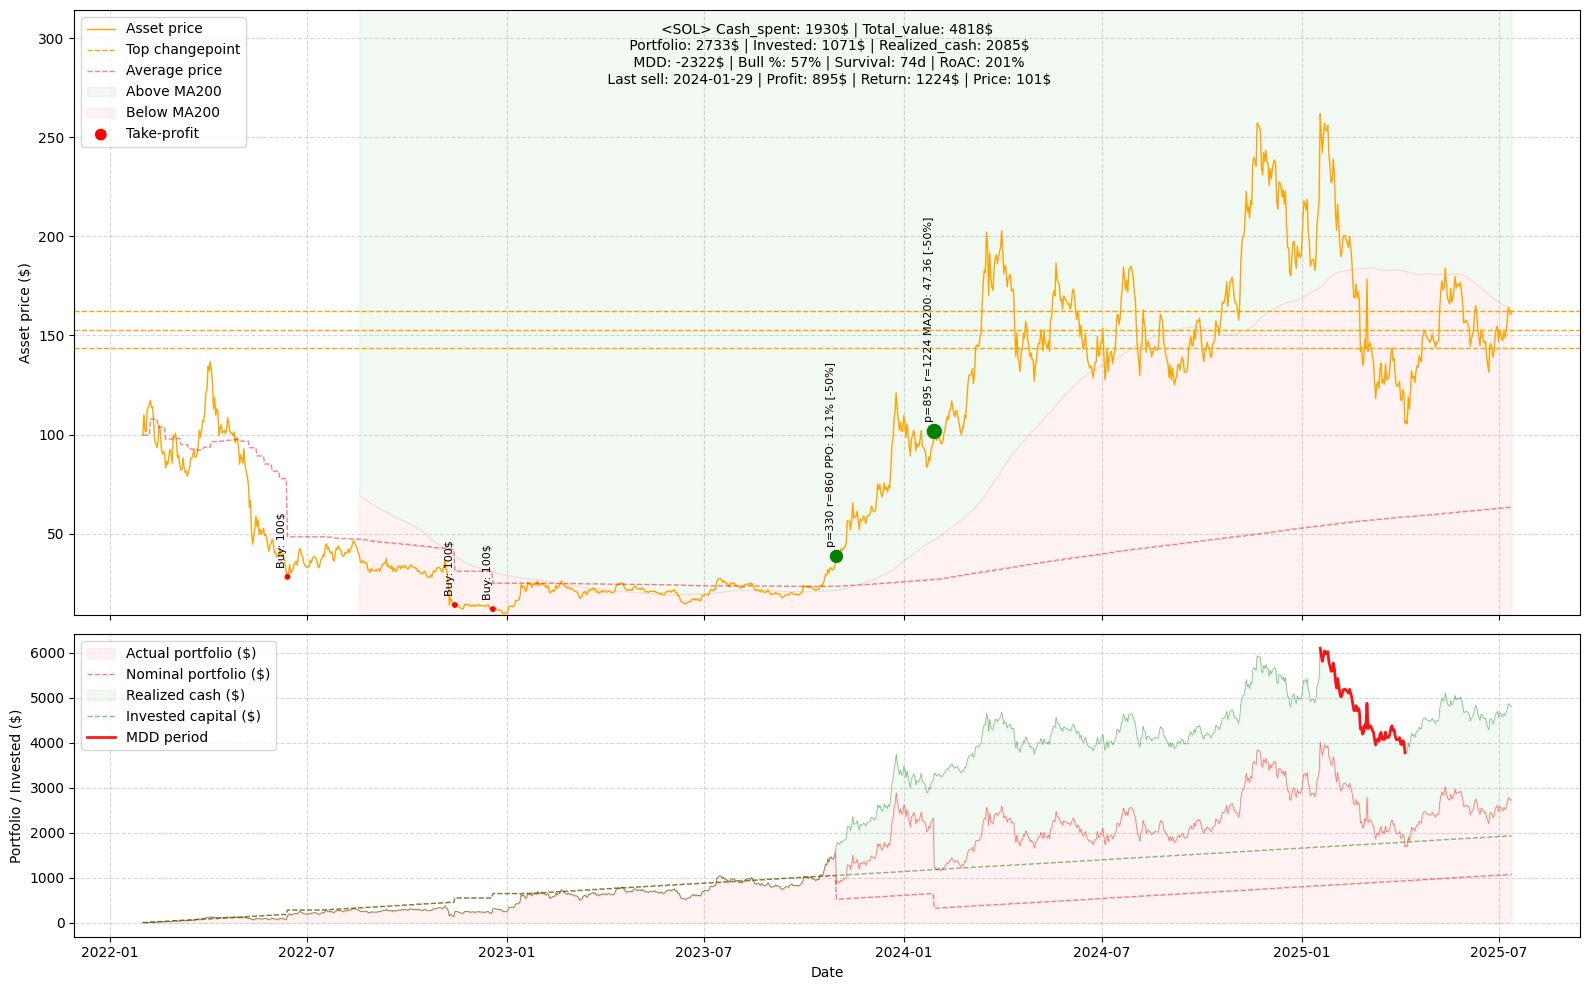

02:27:54 - cmdstanpy - INFO - Chain [1] start processing
02:27:54 - cmdstanpy - INFO - Chain [1] done processing


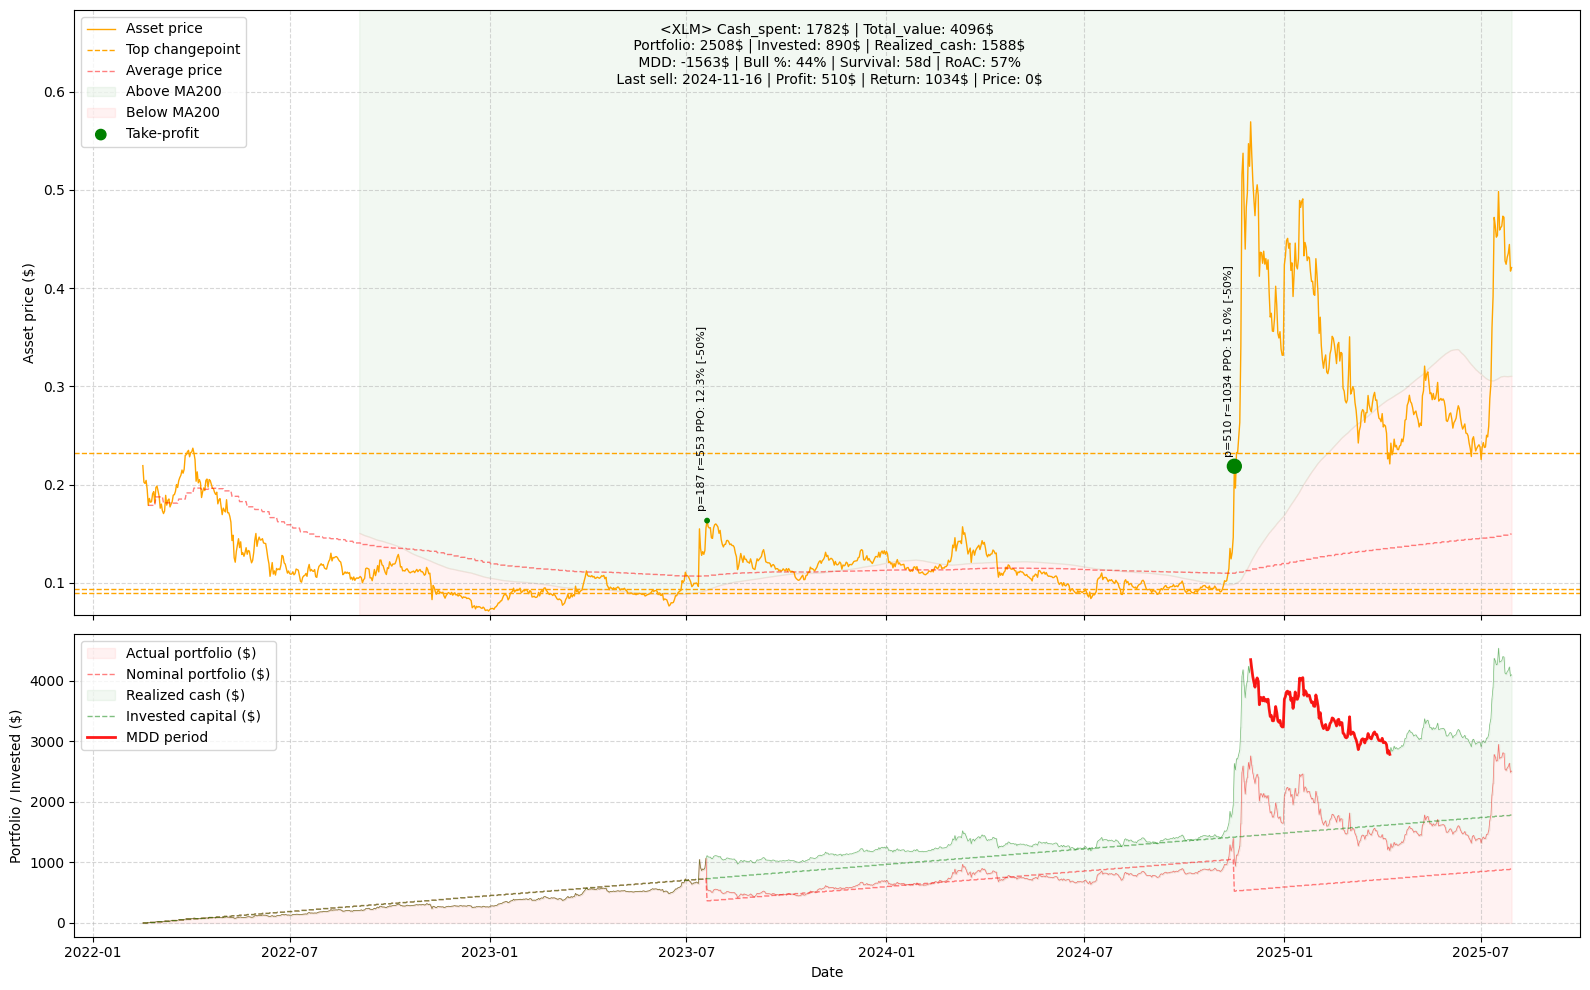

02:27:55 - cmdstanpy - INFO - Chain [1] start processing
02:27:55 - cmdstanpy - INFO - Chain [1] done processing


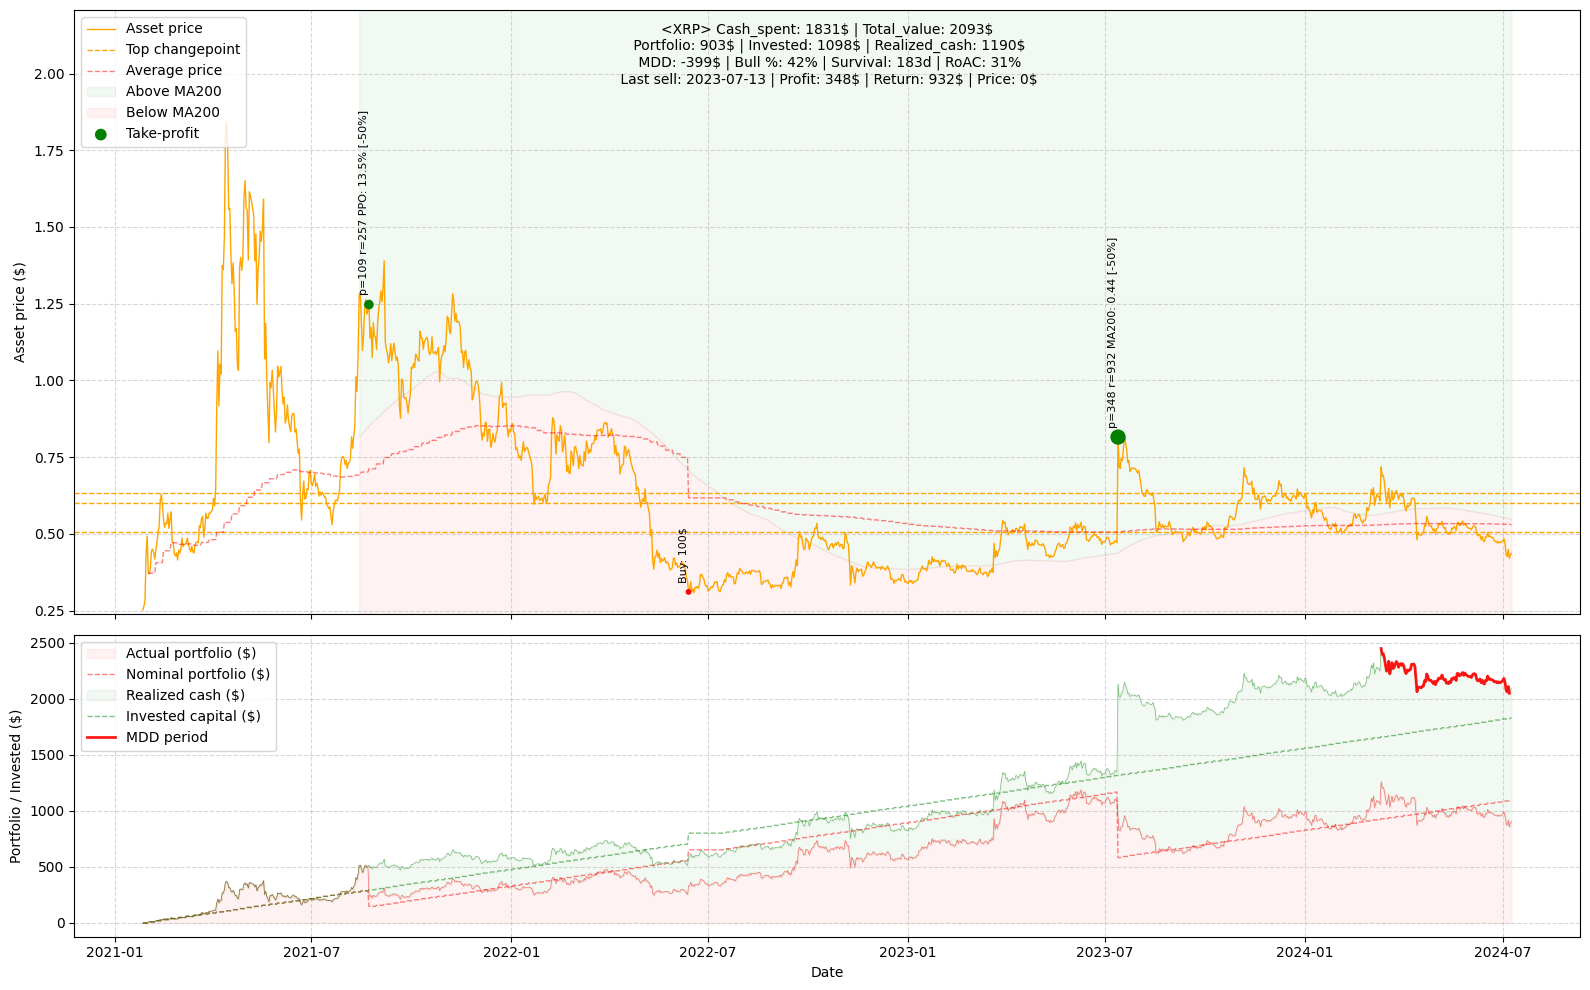

02:27:55 - cmdstanpy - INFO - Chain [1] start processing
02:27:56 - cmdstanpy - INFO - Chain [1] done processing


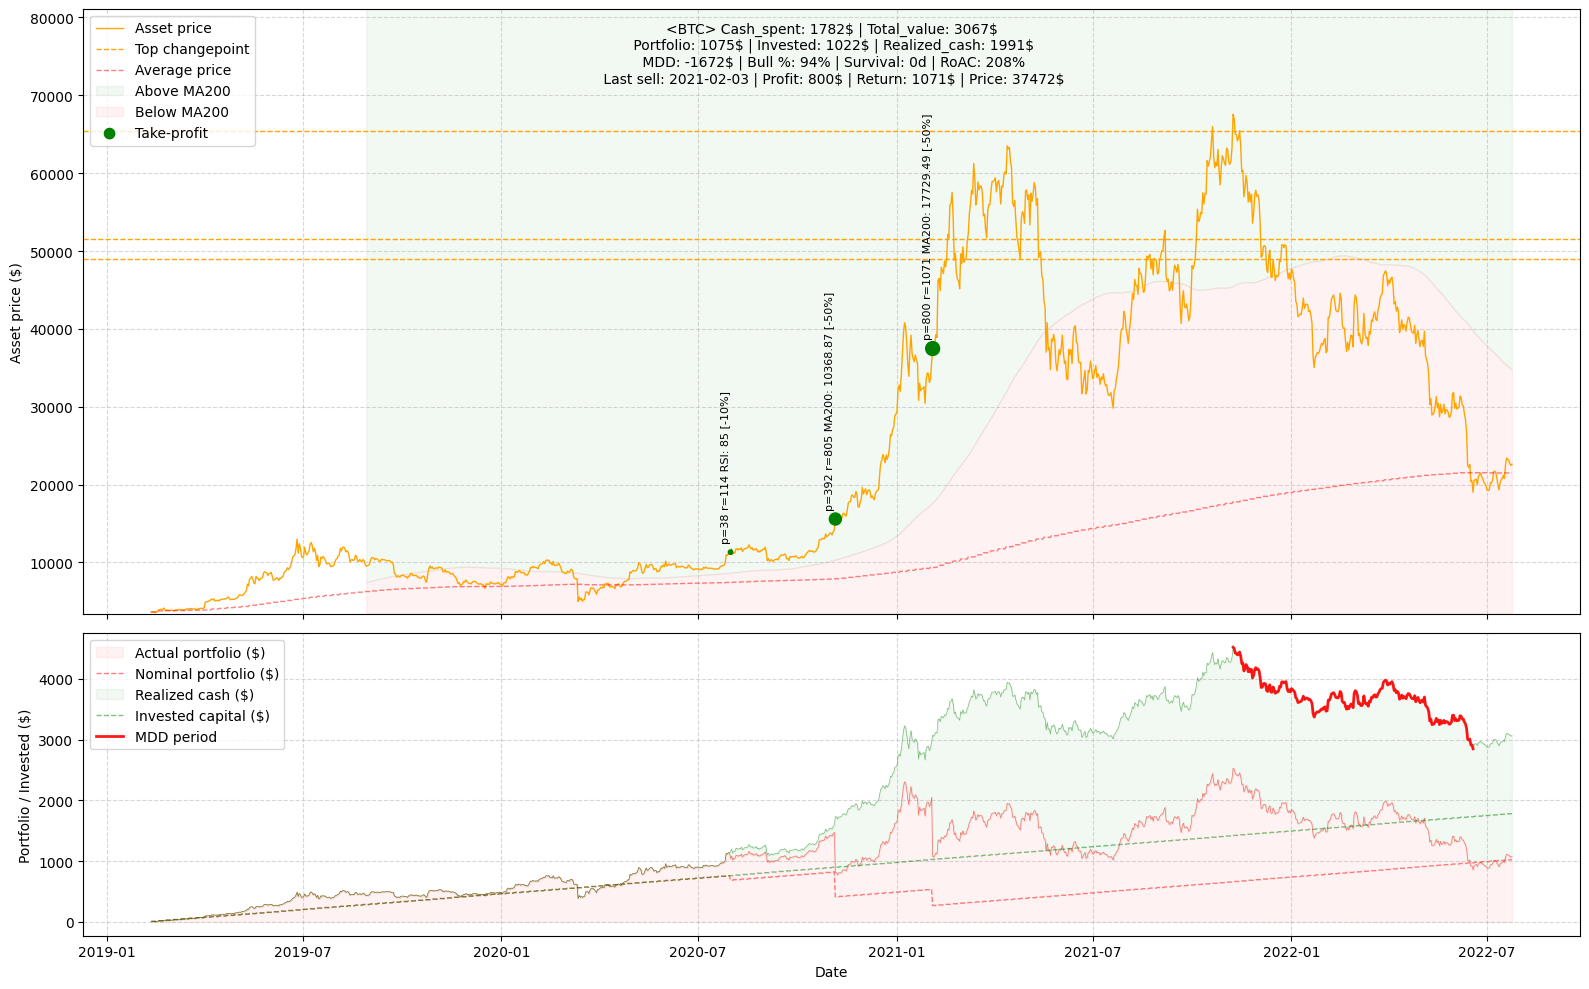

02:27:56 - cmdstanpy - INFO - Chain [1] start processing
02:27:56 - cmdstanpy - INFO - Chain [1] done processing


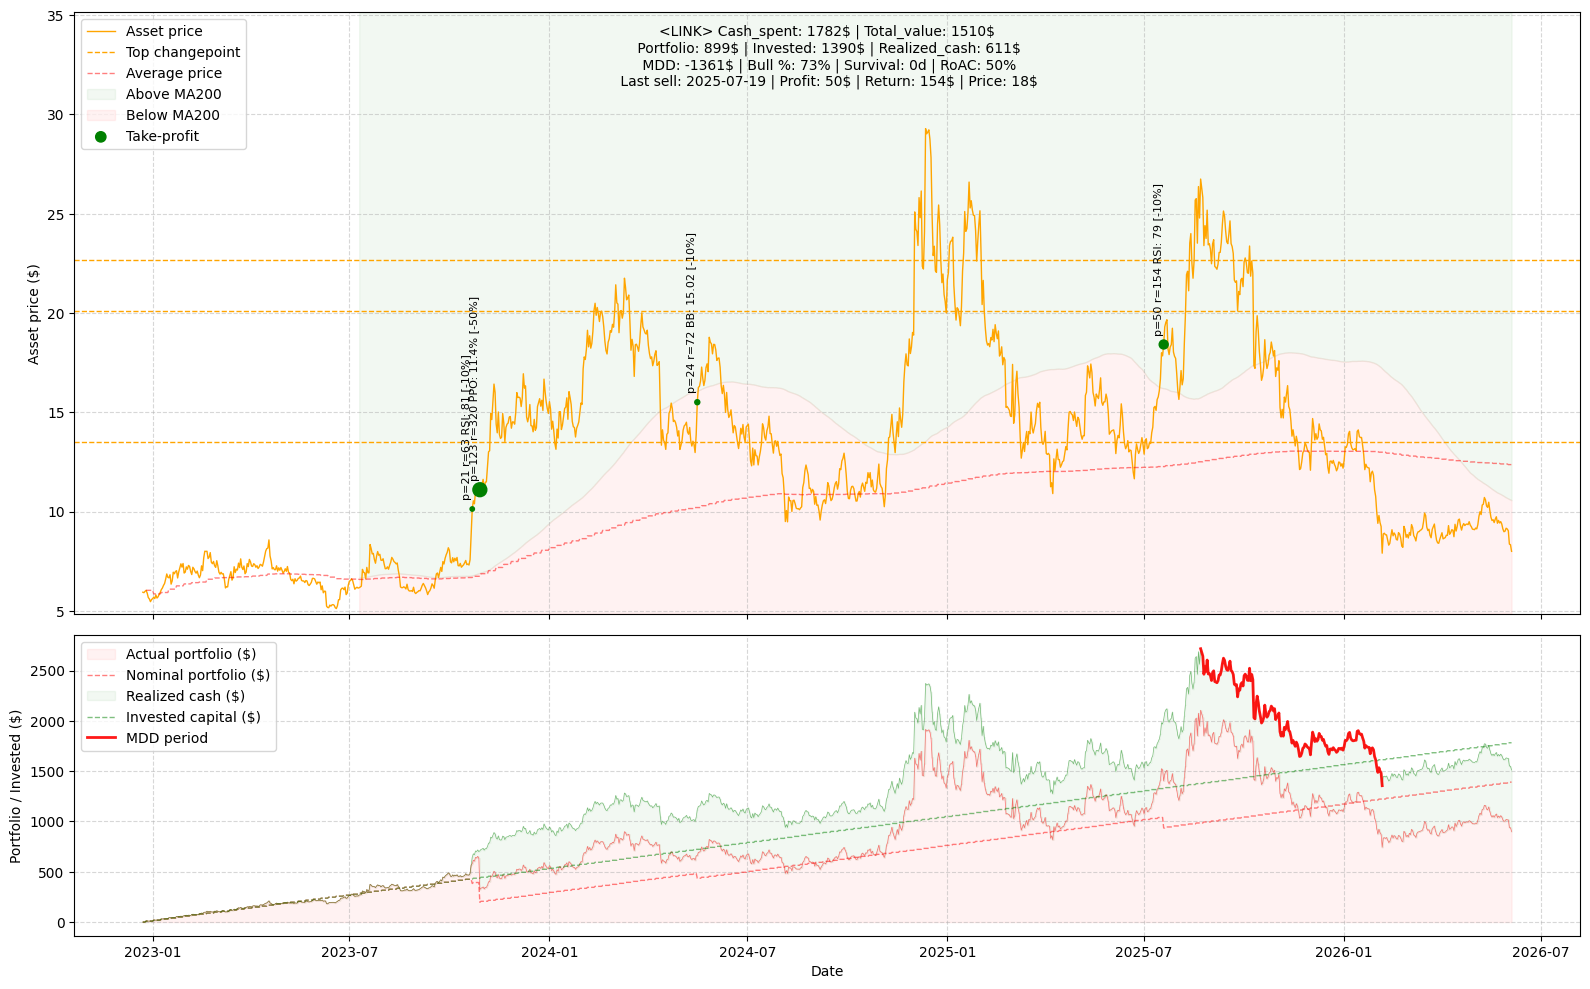

02:27:56 - cmdstanpy - INFO - Chain [1] start processing
02:27:57 - cmdstanpy - INFO - Chain [1] done processing


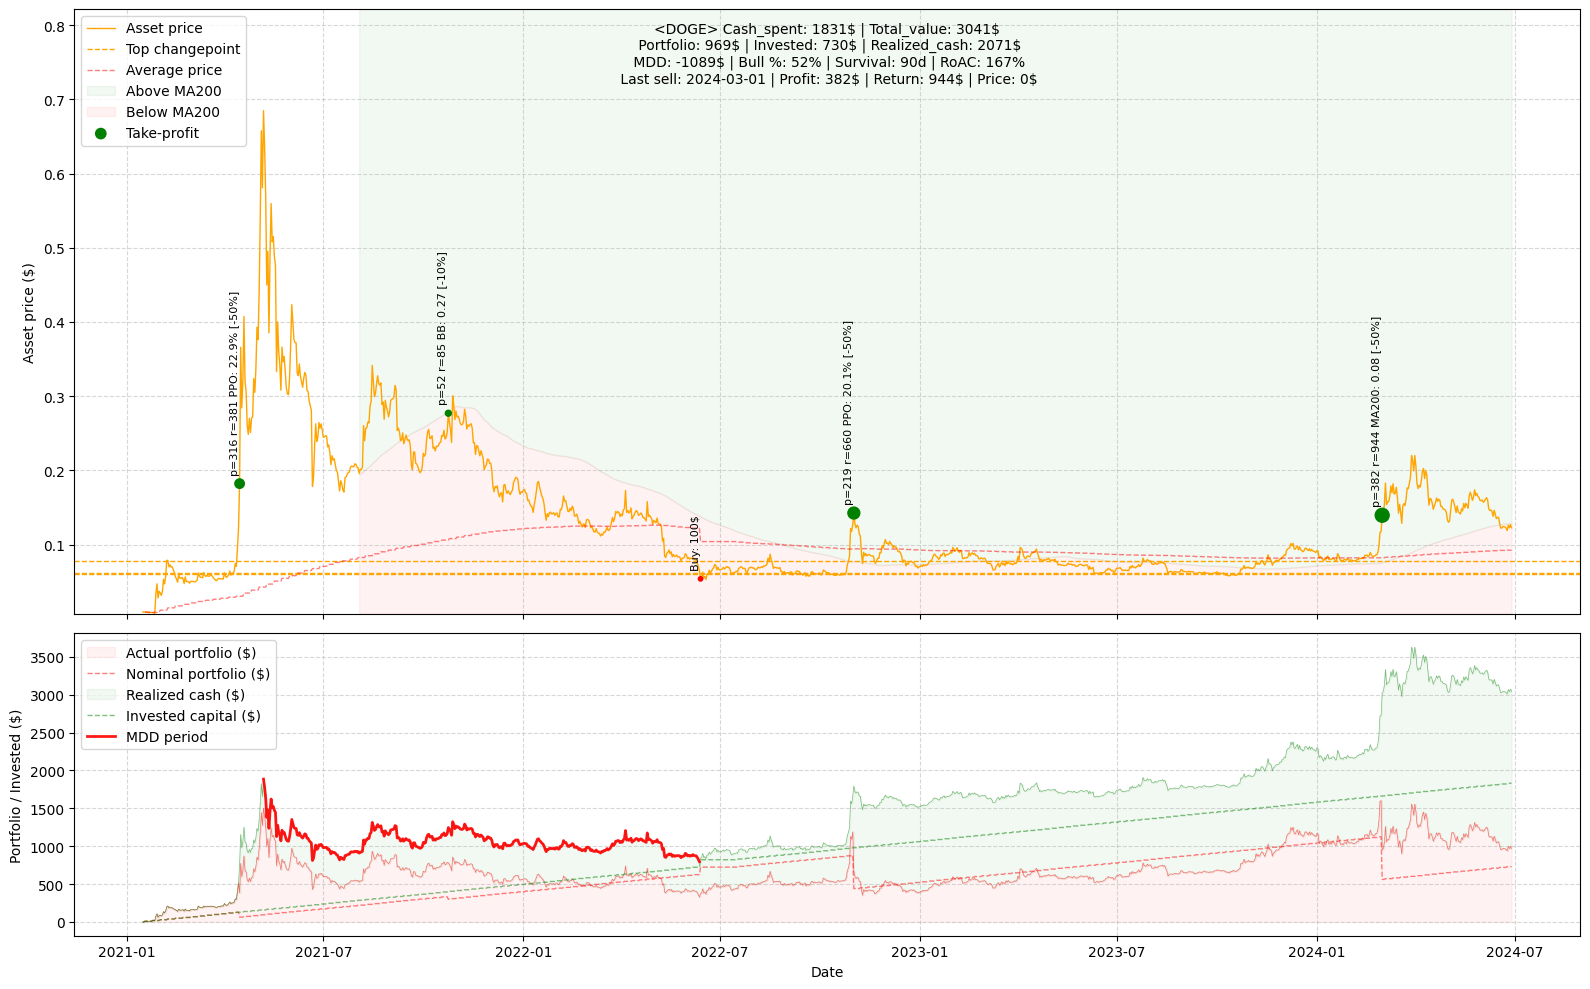

02:27:57 - cmdstanpy - INFO - Chain [1] start processing
02:27:57 - cmdstanpy - INFO - Chain [1] done processing


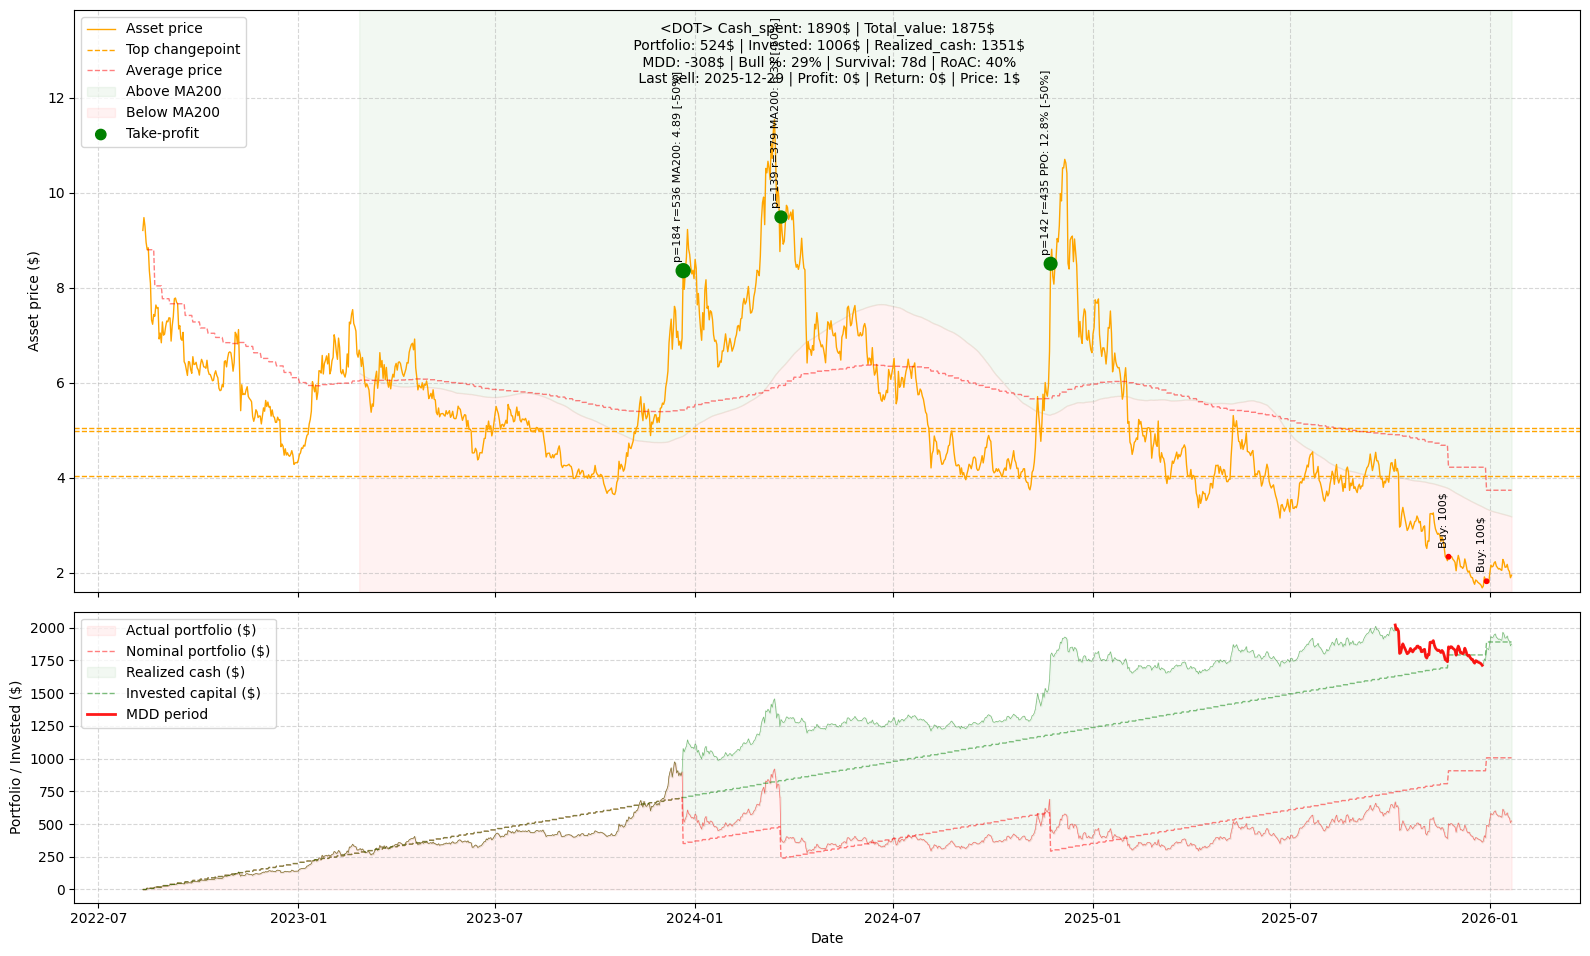

02:27:57 - cmdstanpy - INFO - Chain [1] start processing
02:27:58 - cmdstanpy - INFO - Chain [1] done processing


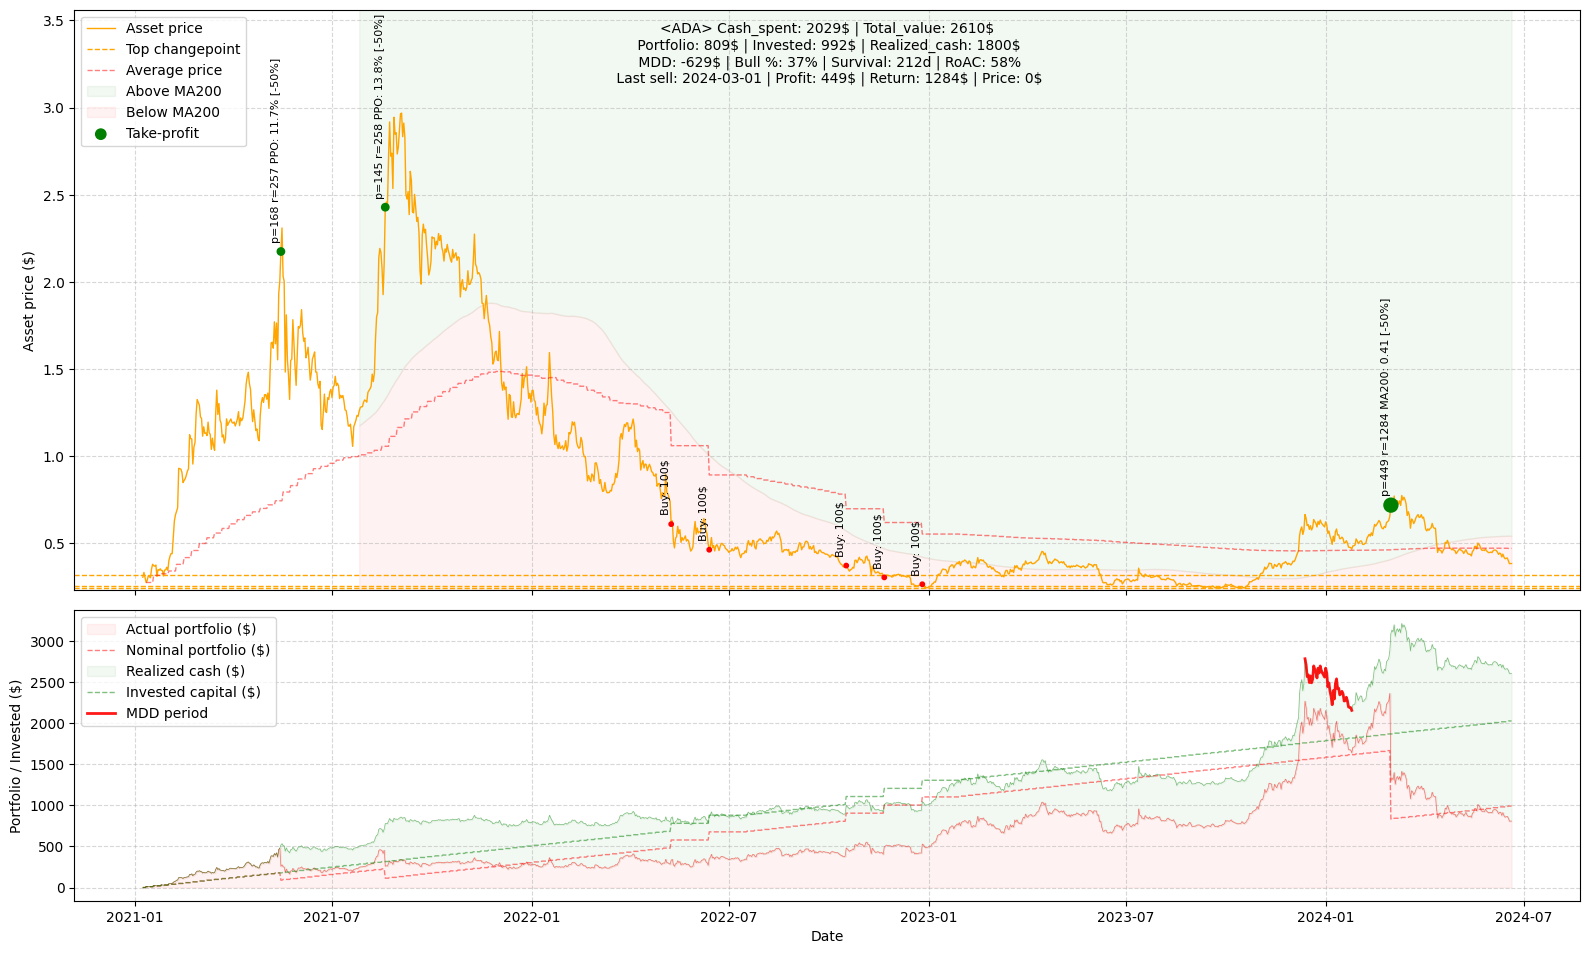

02:27:58 - cmdstanpy - INFO - Chain [1] start processing
02:27:58 - cmdstanpy - INFO - Chain [1] done processing


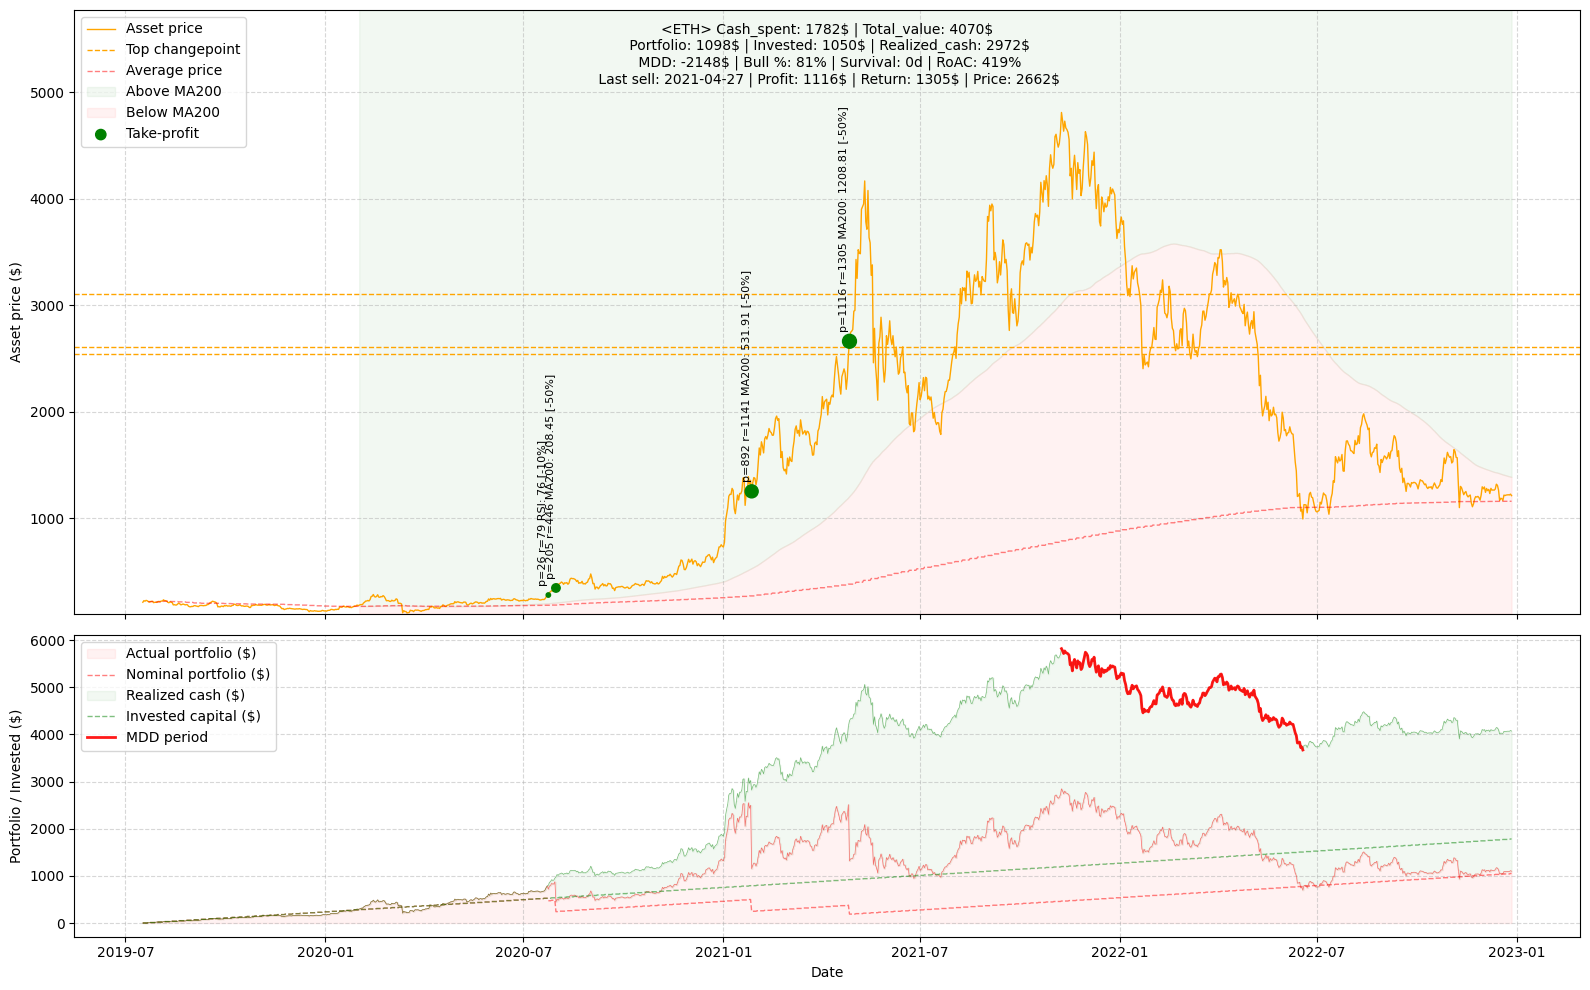

02:27:59 - cmdstanpy - INFO - Chain [1] start processing
02:27:59 - cmdstanpy - INFO - Chain [1] done processing


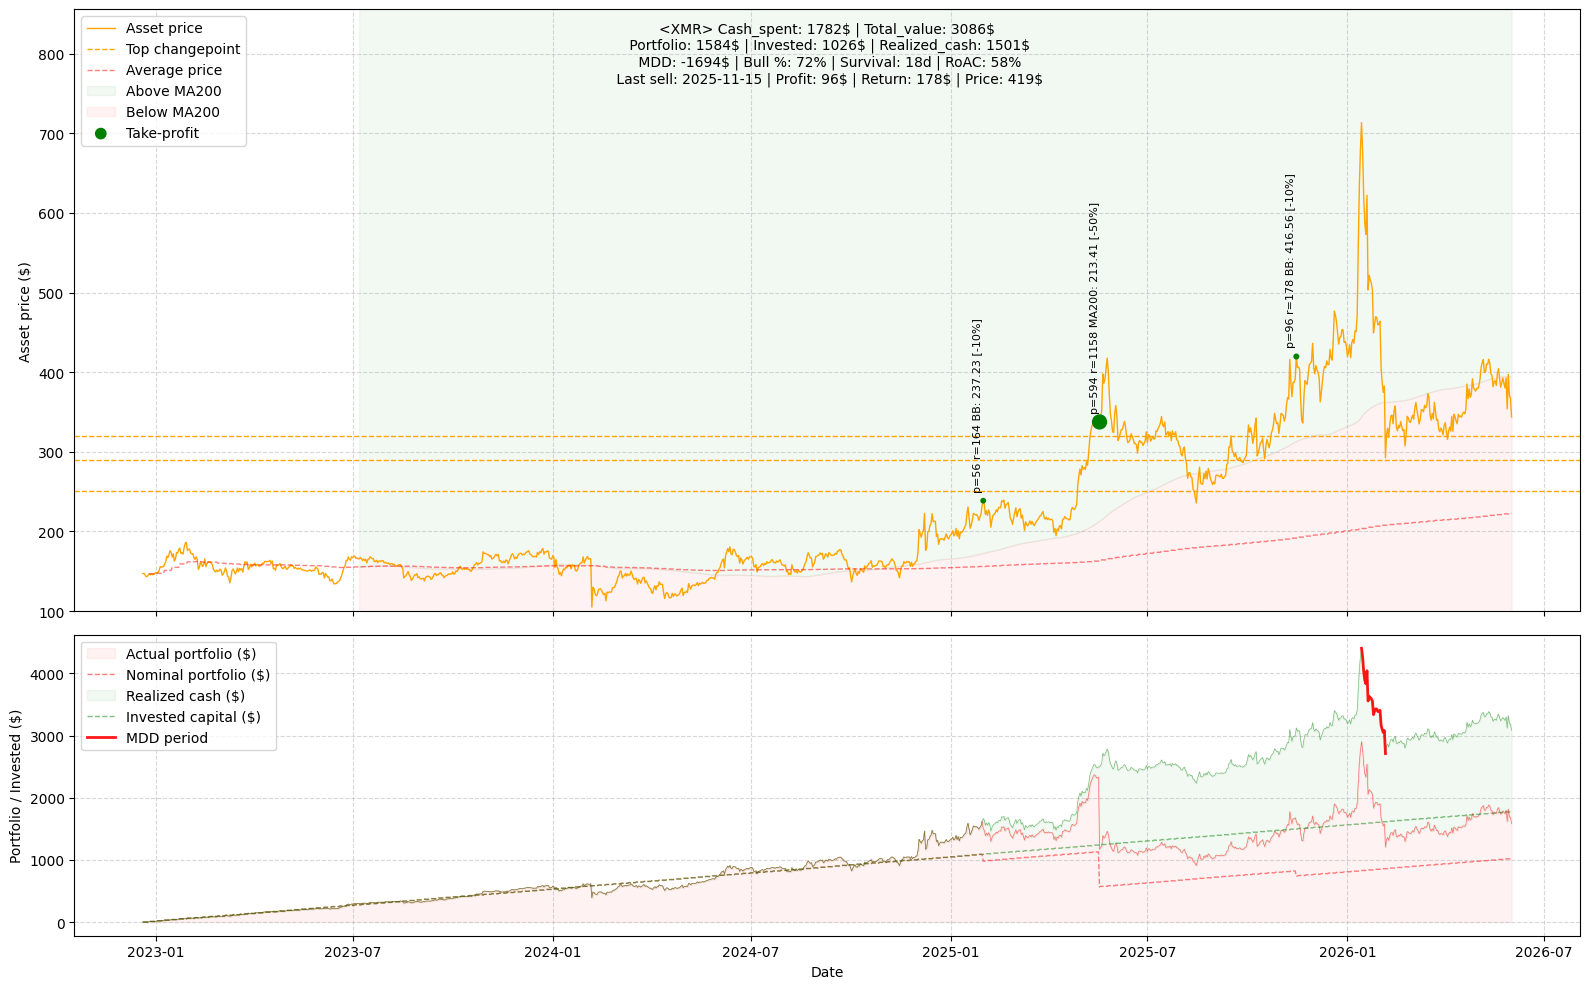

Total invested: $18421.00
Total return: $17160.00
Total value: $30266.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - sequence_length)
    prices = prices.iloc[start:start + sequence_length]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2022-12-20,146.995483,0.000000,0.00,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-12-21,147.331558,0.000000,0.00,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-12-22,145.485336,0.000000,0.00,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-12-23,143.153595,0.000000,0.00,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-12-24,143.466736,0.000000,0.00,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
2026-05-28,353.834320,4.579503,1016.73,1772.1,0.0,0.0,1501.933599,,1620.385349,222.017539,3122.318948
2026-05-29,397.166412,4.579503,1016.73,1772.1,0.0,0.0,1501.933599,,1818.824798,222.017539,3320.758397
2026-05-30,370.426971,4.579503,1016.73,1772.1,0.0,0.0,1501.933599,,1696.371447,222.017539,3198.305046


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(1254)

In [10]:
metrics

{'Target': 'XMR',
 'Cash_spent': 1782,
 'Realized_cash': 1501,
 'Portfolio': 1584,
 'Invested': 1026,
 'Total_value': 3086,
 'Bull_history': 72,
 'Avg_price': np.float64(222.77837464481055),
 'Num_take_profits': 3,
 'MDD': -1694,
 'MA200_survival_days': 18.333333333333325,
 'RoAC': 58}